# Speech Emotion Recognition (RAVDESS)

Reconocimiento de emociones en habla. La lógica reutilizable vive en `src/`; este notebook orquesta.

## Imports y setup

In [1]:
# Ejecutar desde la raíz del repo para que 'import src...' funcione
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

from src import config
from src.data import build_metadata, get_xy
from src.splits import make_split, load_split, assign_split
from src.features.egemaps import extract_egemaps
from src.features.wav2vec import extract_wav2vec
from src.evaluation import grouped_cv
from src.metrics import evaluate
from src.plots import plot_confusion_matrix

# Constantes compartidas
sns.set_theme(style="whitegrid", context="notebook")
REPORTS_DIR = Path("reports"); REPORTS_DIR.mkdir(exist_ok=True)
META_COLS = config.META_COLS
EMOTION_ORDER = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

## Datos y split

Metadata de los 2452 audios + split train/val congelado **por hablante** (speaker-independent, evita data leakage).

In [2]:
metadata = build_metadata()

# Split por hablante, congelado en splits/split.json (se reusa si ya existe)
split = load_split() if config.SPLIT_PATH.exists() else make_split(metadata)
metadata = assign_split(metadata, split)

print(metadata.shape, "| val_actors:", split["val_actors"])
metadata.head()

(2452, 10) | val_actors: [2, 9, 11, 20]


,path,modality,vocal_channel,emotion,intensity,statement,repetition,actor,gender,split
0,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,1,1,male,train
1,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,2,1,male,train
2,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,1,1,male,train
3,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,2,1,male,train
4,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,calm,normal,kids,1,1,male,train


## eGeMAPS

88 features expertas (OpenSMILE), cacheadas; dataset combinado metadata + features.

In [3]:
egemaps_path = config.PROCESSED_DIR / "egemaps.parquet"
if egemaps_path.exists():
    egemaps = pd.read_parquet(egemaps_path)
else:
    egemaps = extract_egemaps(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    egemaps.to_parquet(egemaps_path)

# Dataset combinado: metadata (con split) + 88 features
dataset = metadata.merge(egemaps, left_on="path", right_index=True, how="left")
dataset.to_parquet(config.PROCESSED_DIR / "dataset.parquet")
print("eGeMAPS:", egemaps.shape, "| dataset:", dataset.shape)

eGeMAPS: (2452, 88) | dataset: (2452, 98)


## wav2vec

Embeddings SSL (`wav2vec2-base`, 768-dim, mean-pooled), cacheados; dataset combinado.

In [4]:
w2v_path = config.PROCESSED_DIR / "wav2vec.parquet"
if w2v_path.exists():
    wav2vec = pd.read_parquet(w2v_path)
else:
    wav2vec = extract_wav2vec(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    wav2vec.to_parquet(w2v_path)

dataset_w2v = metadata.merge(wav2vec, left_on="path", right_index=True, how="left")
dataset_w2v.to_parquet(config.PROCESSED_DIR / "dataset_wav2vec.parquet")
print("wav2vec:", wav2vec.shape, "| dataset_wav2vec:", dataset_w2v.shape)

wav2vec: (2452, 768) | dataset_wav2vec: (2452, 778)


# EDA

Exploración de clases y features (sobre speech).

In [5]:
speech = dataset[dataset["vocal_channel"] == "speech"].copy()
FEAT_COLS = [c for c in dataset.columns if c not in META_COLS]

## Balance de clases

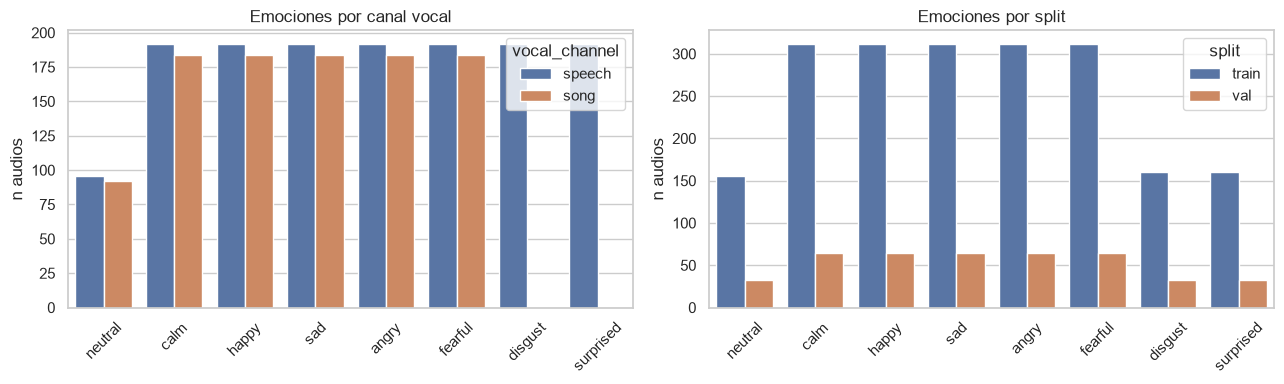

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=dataset, x="emotion", hue="vocal_channel", order=EMOTION_ORDER, ax=axes[0])
axes[0].set_title("Emociones por canal vocal"); axes[0].set_xlabel(""); axes[0].set_ylabel("n audios"); axes[0].tick_params(axis="x", rotation=45)
sns.countplot(data=dataset, x="emotion", hue="split", order=EMOTION_ORDER, ax=axes[1])
axes[1].set_title("Emociones por split"); axes[1].set_xlabel(""); axes[1].set_ylabel("n audios"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_class_balance.png", dpi=110, bbox_inches="tight"); plt.show()

## Distribuciones por emoción (speech)

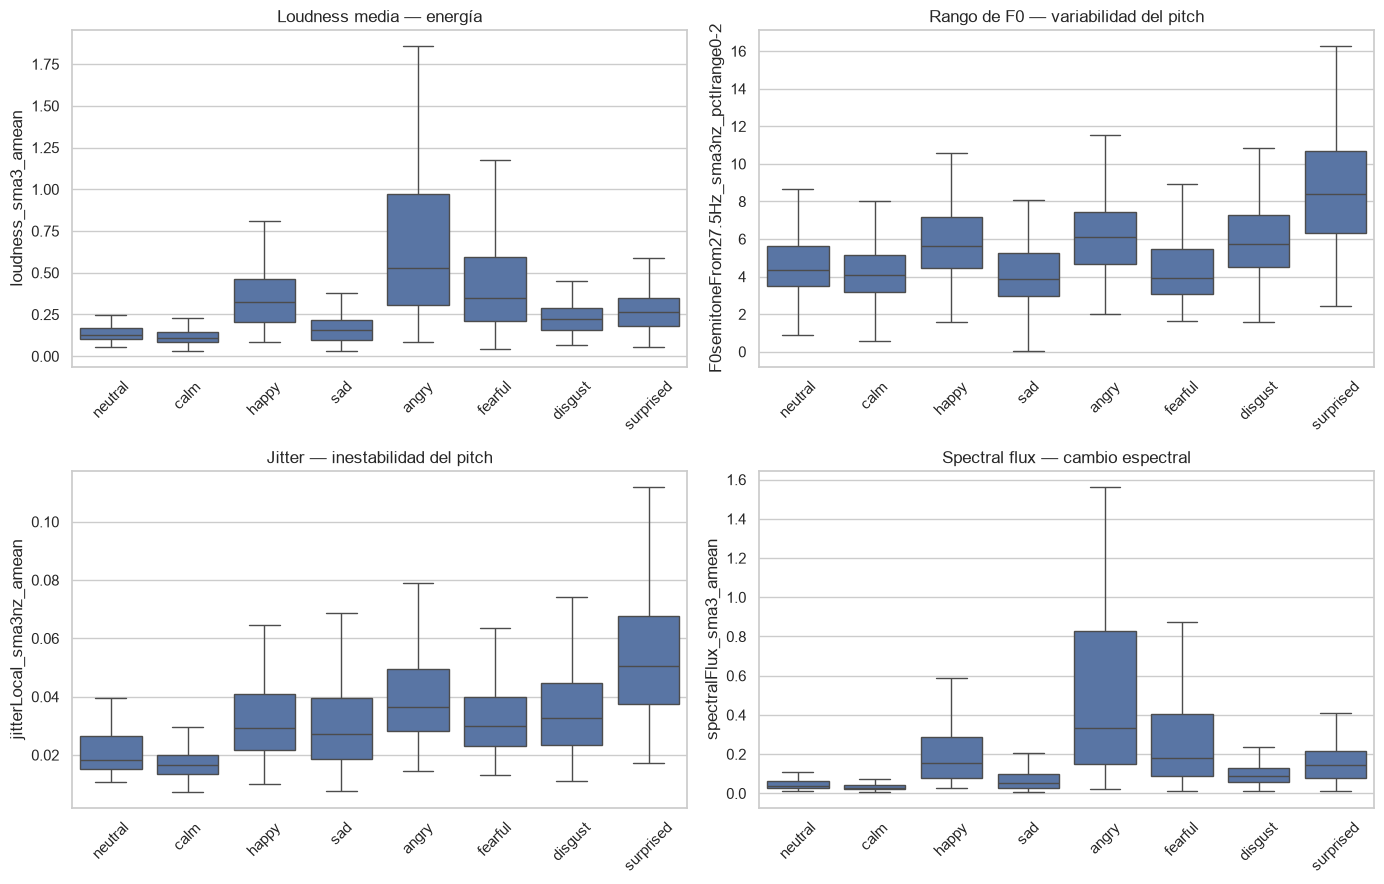

In [7]:
top_feats = [
    ("loudness_sma3_amean", "Loudness media — energía"),
    ("F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "Rango de F0 — variabilidad del pitch"),
    ("jitterLocal_sma3nz_amean", "Jitter — inestabilidad del pitch"),
    ("spectralFlux_sma3_amean", "Spectral flux — cambio espectral"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feat, title) in zip(axes.ravel(), top_feats):
    sns.boxplot(data=speech, x="emotion", y=feat, order=EMOTION_ORDER, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_feature_dists.png", dpi=110, bbox_inches="tight"); plt.show()

## PCA 2D por emoción (speech)

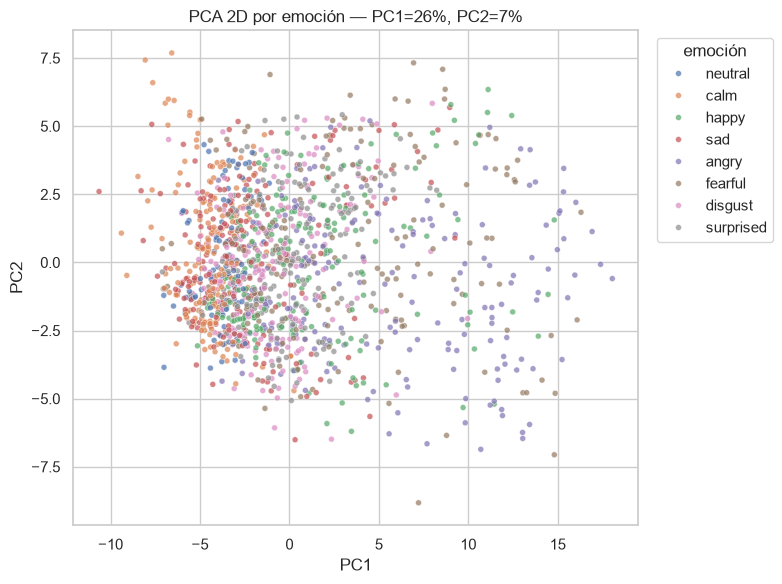

In [8]:
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

X_pca = np.clip(RobustScaler().fit_transform(speech[FEAT_COLS]), -5, 5)
pca = PCA(n_components=2, random_state=config.RANDOM_SEED).fit(X_pca)
pcs = pca.transform(X_pca)
speech["PC1"], speech["PC2"] = pcs[:, 0], pcs[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="emotion", hue_order=EMOTION_ORDER, s=18, alpha=0.7, ax=ax)
ax.set_title(f"PCA 2D por emoción — PC1={var[0]:.0f}%, PC2={var[1]:.0f}%")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_pca_emotion.png", dpi=110, bbox_inches="tight"); plt.show()

## Confound: género

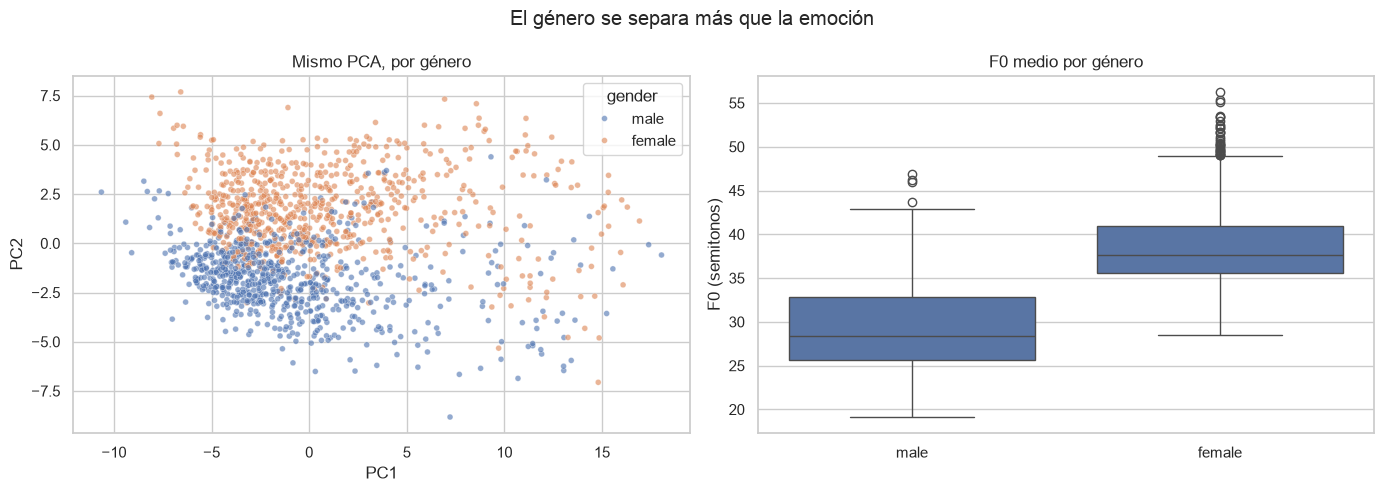

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="gender", s=18, alpha=0.6, ax=axes[0])
axes[0].set_title("Mismo PCA, por género")
sns.boxplot(data=speech, x="gender", y="F0semitoneFrom27.5Hz_sma3nz_amean", ax=axes[1])
axes[1].set_title("F0 medio por género"); axes[1].set_xlabel(""); axes[1].set_ylabel("F0 (semitonos)")
fig.suptitle("El género se separa más que la emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_confound_gender.png", dpi=110, bbox_inches="tight"); plt.show()

# Baseline model — Random Forest

Mismo modelo y validación (`GroupKFold` por actor, `class_weight="balanced"`) sobre ambas representaciones. Speech-only, chance = 12.5%.

## RF — eGeMAPS

In [10]:
X, y, groups = get_xy(dataset, vocal_channel="speech")
rf = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
oof_pred, folds = grouped_cv(rf, X, y, groups, n_splits=5)

overall = evaluate(y, oof_pred, labels=EMOTION_ORDER)
fold_macro = np.array([m["macro_f1"] for m in folds])
print(f"eGeMAPS RF -> acc {overall['accuracy']:.3f} | macro-F1 {overall['macro_f1']:.3f} (CV {fold_macro.mean():.3f} ± {fold_macro.std():.3f})")

eGeMAPS RF -> acc 0.465 | macro-F1 0.449 (CV 0.447 ± 0.032)


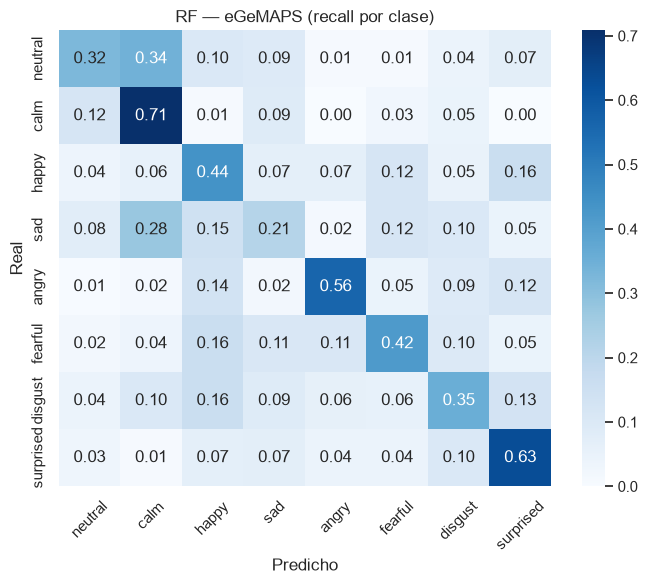

In [11]:
fig, ax = plot_confusion_matrix(y, oof_pred, labels=EMOTION_ORDER, normalize="true", title="RF — eGeMAPS (recall por clase)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "rf_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

## RF — wav2vec

In [12]:
Xw, yw, gw = get_xy(dataset_w2v, vocal_channel="speech")
rf_w2v = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
oof_w2v, folds_w2v = grouped_cv(rf_w2v, Xw, yw, gw, n_splits=5)

overall_w2v = evaluate(yw, oof_w2v, labels=EMOTION_ORDER)
fold_macro_w2v = np.array([m["macro_f1"] for m in folds_w2v])
print(f"wav2vec RF -> acc {overall_w2v['accuracy']:.3f} | macro-F1 {overall_w2v['macro_f1']:.3f} (CV {fold_macro_w2v.mean():.3f} ± {fold_macro_w2v.std():.3f})")

wav2vec RF -> acc 0.461 | macro-F1 0.443 (CV 0.441 ± 0.027)


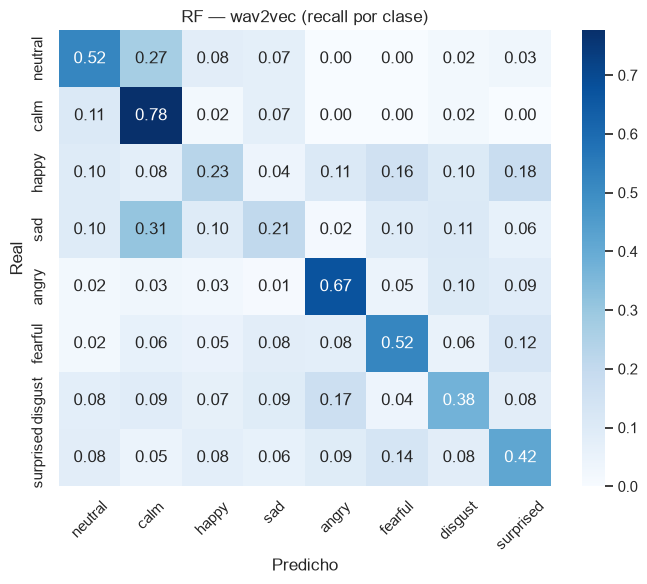

In [13]:
fig, ax = plot_confusion_matrix(yw, oof_w2v, labels=EMOTION_ORDER, normalize="true", title="RF — wav2vec (recall por clase)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "wav2vec_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

## RF — eGeMAPS + wav2vec (combinado)

In [14]:
# Fusión: 88 features eGeMAPS + 768 embeddings wav2vec = 856 features
dataset_all = dataset.merge(wav2vec, left_on="path", right_index=True, how="left")
Xa, ya, ga = get_xy(dataset_all, vocal_channel="speech")
print("X combinado:", Xa.shape)

rf_all = RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
oof_all, folds_all = grouped_cv(rf_all, Xa, ya, ga, n_splits=5)

overall_all = evaluate(ya, oof_all, labels=EMOTION_ORDER)
fold_macro_all = np.array([m["macro_f1"] for m in folds_all])
print(f"combinado RF -> acc {overall_all['accuracy']:.3f} | macro-F1 {overall_all['macro_f1']:.3f} (CV {fold_macro_all.mean():.3f} ± {fold_macro_all.std():.3f})")

X combinado: (1440, 856)


combinado RF -> acc 0.494 | macro-F1 0.480 (CV 0.478 ± 0.028)


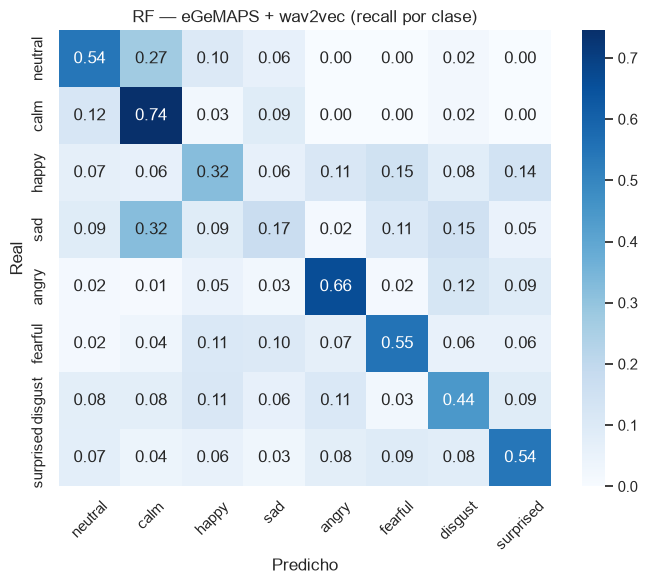

In [15]:
fig, ax = plot_confusion_matrix(ya, oof_all, labels=EMOTION_ORDER, normalize="true", title="RF — eGeMAPS + wav2vec (recall por clase)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "combined_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

## Comparación (eGeMAPS vs wav2vec vs combinado)

In [16]:
summary = pd.DataFrame({
    "eGeMAPS (88)":    {k: overall[k]     for k in ["accuracy", "macro_f1", "weighted_f1"]},
    "wav2vec (768)":   {k: overall_w2v[k] for k in ["accuracy", "macro_f1", "weighted_f1"]},
    "combinado (856)": {k: overall_all[k] for k in ["accuracy", "macro_f1", "weighted_f1"]},
}).round(3)
per_class = pd.DataFrame({
    "eGeMAPS":   overall["per_class_f1"],
    "wav2vec":   overall_w2v["per_class_f1"],
    "combinado": overall_all["per_class_f1"],
}).reindex(EMOTION_ORDER).round(3)
print(summary, "\n")
print(per_class)

             eGeMAPS (88)  wav2vec (768)  combinado (856)
accuracy            0.465          0.461            0.494
macro_f1            0.449          0.443            0.480
weighted_f1         0.457          0.445            0.482 

           eGeMAPS  wav2vec  combinado
neutral      0.325    0.410      0.441
calm         0.595    0.614      0.612
happy        0.403    0.284      0.354
sad          0.250    0.259      0.218
angry        0.603    0.628      0.646
fearful      0.455    0.521      0.568
disgust      0.378    0.402      0.449
surprised    0.580    0.422      0.549


# Investigación — capas de wav2vec

¿Qué capa da mejores features para emoción? El último hidden state está sesgado al objetivo de
pre-entrenamiento; la info prosódica/emocional suele estar en capas intermedias. Probamos el
mean-pool de **cada** capa + el mismo RF (GroupKFold por actor, speech-only).

In [17]:
from src.features.wav2vec import extract_wav2vec_layers

# Embeddings de las 13 capas (cache .npz)
layers_path = config.PROCESSED_DIR / "wav2vec_layers.npz"
if layers_path.exists():
    _npz = np.load(layers_path, allow_pickle=True)
    layer_emb, layer_paths = _npz["emb"], [str(p) for p in _npz["paths"]]
else:
    layer_emb, layer_paths = extract_wav2vec_layers(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(layers_path, emb=layer_emb, paths=np.array(layer_paths, dtype=object))
assert layer_paths == metadata["path"].tolist()

# Barrido: RF por capa (cache parquet)
sweep_path = config.PROCESSED_DIR / "wav2vec_layer_sweep.parquet"
if sweep_path.exists():
    sweep = pd.read_parquet(sweep_path)
else:
    mask = (metadata["vocal_channel"] == "speech").to_numpy()
    ys, gs = metadata.loc[mask, "emotion"], metadata.loc[mask, "actor"]
    rows = []
    for l in range(layer_emb.shape[1]):
        rf_l = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
        oof_l, _ = grouped_cv(rf_l, layer_emb[mask, l, :], ys, gs, n_splits=5)
        m = evaluate(ys, oof_l, labels=EMOTION_ORDER)
        rows.append({"layer": l, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
    sweep = pd.DataFrame(rows)
    sweep.to_parquet(sweep_path)
sweep

,layer,accuracy,macro_f1
0,0,0.472222,0.461267
1,1,0.497222,0.480091
2,2,0.529861,0.513858
3,3,0.538889,0.522706
4,4,0.555556,0.538875
5,5,0.584722,0.570671
6,6,0.592361,0.575530
7,7,0.588194,0.574737
8,8,0.592361,0.578493
9,9,0.552083,0.536499


## Macro-F1 según la capa

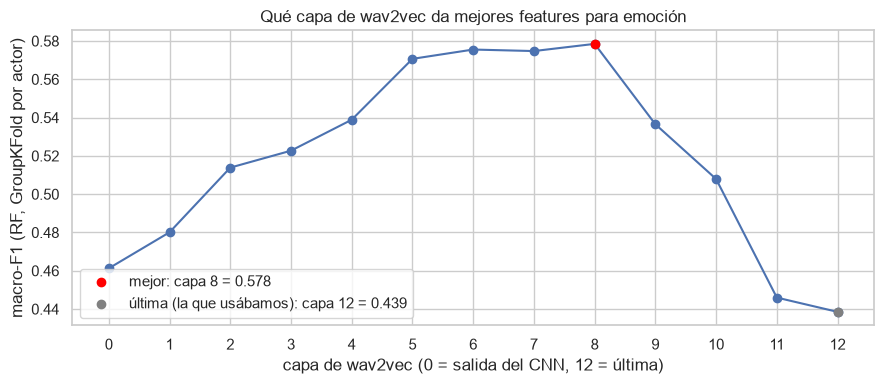

In [18]:
best = sweep.loc[sweep["macro_f1"].idxmax()]
last = sweep.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sweep["layer"], sweep["macro_f1"], marker="o")
ax.scatter([best["layer"]], [best["macro_f1"]], color="red", zorder=5,
           label=f"mejor: capa {int(best['layer'])} = {best['macro_f1']:.3f}")
ax.scatter([last["layer"]], [last["macro_f1"]], color="gray", zorder=5,
           label=f"última (la que usábamos): capa {int(last['layer'])} = {last['macro_f1']:.3f}")
ax.set_xlabel("capa de wav2vec (0 = salida del CNN, 12 = última)")
ax.set_ylabel("macro-F1 (RF, GroupKFold por actor)")
ax.set_title("Qué capa de wav2vec da mejores features para emoción")
ax.set_xticks(range(len(sweep))); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "wav2vec_layer_sweep.png", dpi=110, bbox_inches="tight"); plt.show()